# Taller — Abandono de producto financiero
Regresión logística en Python · Clase 9 · Machine Learning aplicado a Economía y Finanzas · FCEA · 2026-2

**Juan Diego Zutta Arcos**

Pregunta: dadas las características del cliente, ¿cuál es $P(\text{abandono}=1 \mid x)$? Se estima con `smf.logit` (y `smf.ols` como contraste), partición 70/30 con `default_rng(8)`.

## 1. Estructura de los datos

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.formula.api as smf
from scipy.stats import chi2_contingency

pd.set_option("display.width", 140)
pd.set_option("display.max_columns", 20)

df_crudo = pd.read_csv("abandono_producto_financiero.csv", encoding="utf-8")
print("Dimensión cruda:", df_crudo.shape)
df_crudo.head()

Dimensión cruda: (10000, 14)


,numero_fila,id_cliente,apellido,puntaje_crediticio,pais,sexo,edad,antiguedad,saldo,numero_productos,tiene_tarjeta,miembro_activo,salario_estimado,abandono
0,1,15634602,Hargrave,619,Francia,Mujer,42,2,0.00,1,1,1,101348.88,1
1,2,15647311,Hill,608,España,Mujer,41,1,83807.86,1,0,1,112542.58,0
2,3,15619304,Onio,502,Francia,Mujer,42,8,159660.80,3,1,0,113931.57,1
3,4,15701354,Boni,699,Francia,Mujer,39,1,0.00,2,0,0,93826.63,0
4,5,15737888,Mitchell,850,España,Mujer,43,2,125510.82,1,1,1,79084.10,0


In [2]:
print(list(df_crudo.columns))
df_crudo.dtypes

['numero_fila', 'id_cliente', 'apellido', 'puntaje_crediticio', 'pais', 'sexo', 'edad', 'antiguedad', 'saldo', 'numero_productos', 'tiene_tarjeta', 'miembro_activo', 'salario_estimado', 'abandono']


numero_fila             int64
id_cliente              int64
apellido                  str
puntaje_crediticio      int64
pais                      str
sexo                      str
edad                    int64
antiguedad              int64
saldo                 float64
numero_productos        int64
tiene_tarjeta           int64
miembro_activo          int64
salario_estimado      float64
abandono                int64
dtype: object

In [3]:
df_crudo.describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
numero_fila,10000.0,5000.50,2886.90,1.00,2500.75,5000.50,7500.25,10000.00
id_cliente,10000.0,15690940.57,71936.19,15565701.00,15628528.25,15690738.00,15753233.75,15815690.00
puntaje_crediticio,10000.0,650.53,96.65,350.00,584.00,652.00,718.00,850.00
edad,10000.0,38.92,10.49,18.00,32.00,37.00,44.00,92.00
antiguedad,10000.0,5.01,2.89,0.00,3.00,5.00,7.00,10.00
saldo,10000.0,76485.89,62397.41,0.00,0.00,97198.54,127644.24,250898.09
numero_productos,10000.0,1.53,0.58,1.00,1.00,1.00,2.00,4.00
tiene_tarjeta,10000.0,0.71,0.46,0.00,0.00,1.00,1.00,1.00
miembro_activo,10000.0,0.52,0.50,0.00,0.00,1.00,1.00,1.00
salario_estimado,10000.0,100090.24,57510.49,11.58,51002.11,100193.92,149388.25,199992.48


In [4]:
df = df_crudo.drop(columns=["numero_fila", "id_cliente", "apellido"]).copy()
df["pais"] = pd.Categorical(df["pais"], categories=["Francia", "Alemania", "España"])
df["sexo"] = pd.Categorical(df["sexo"], categories=["Mujer", "Hombre"])
df["abandono"] = df["abandono"].astype(int)

cuantitativas = ["puntaje_crediticio", "edad", "antiguedad", "saldo", "numero_productos", "salario_estimado"]
categoricas_binarias = ["pais", "sexo", "tiene_tarjeta", "miembro_activo", "abandono"]
print("Dimensión para el modelo:", df.shape)
print("Cuantitativas (", len(cuantitativas), "):", cuantitativas)
print("Categóricas o binarias (", len(categoricas_binarias), "):", categoricas_binarias)
print("Niveles de pais:", list(df["pais"].cat.categories), "· de sexo:", list(df["sexo"].cat.categories))
print("Faltantes totales:", int(df.isna().sum().sum()))
df.dtypes

Dimensión para el modelo: (10000, 11)
Cuantitativas ( 6 ): ['puntaje_crediticio', 'edad', 'antiguedad', 'saldo', 'numero_productos', 'salario_estimado']
Categóricas o binarias ( 5 ): ['pais', 'sexo', 'tiene_tarjeta', 'miembro_activo', 'abandono']
Niveles de pais: ['Francia', 'Alemania', 'España'] · de sexo: ['Mujer', 'Hombre']
Faltantes totales: 0


puntaje_crediticio       int64
pais                  category
sexo                  category
edad                     int64
antiguedad               int64
saldo                  float64
numero_productos         int64
tiene_tarjeta            int64
miembro_activo           int64
salario_estimado       float64
abandono                 int64
dtype: object

### Respuestas — Sección 1

**1. ¿Cuántas variables tiene la base cruda? ¿Cuántas quedan para el modelo?**
La base cruda tiene **14 variables** y 10.000 clientes. Al quitar los tres identificadores (`numero_fila`, `id_cliente`, `apellido`) quedan **11 variables**: 10 explicativas y la respuesta `abandono`. No hay valores faltantes.

**2. ¿Cuántas son cuantitativas?**
**6**: `puntaje_crediticio`, `edad`, `antiguedad`, `saldo`, `numero_productos` y `salario_estimado`. `numero_productos` es un entero, pero el diccionario lo trata como continuo.

**3. ¿Cuántas son categóricas o binarias (incluyendo `abandono`)?**
**5**: dos categóricas (`pais` con 3 niveles y `sexo` con 2) y tres binarias 0/1 (`tiene_tarjeta`, `miembro_activo` y `abandono`).

**4. ¿Qué implica esta mezcla para el logit en Python?**
Las binarias 0/1 y las cuantitativas entran tal cual: su coeficiente es el cambio en log-odds por una unidad. Las categóricas de texto no se pueden multiplicar por un coeficiente. `C(pais)` y `C(sexo)` le piden a la fórmula que cree las dummies automáticamente, dejando por fuera la **categoría de referencia** (Francia y Mujer, porque son el primer nivel del `category`). Así se evita la trampa de las dummies (colinealidad perfecta con el intercepto) y cada coeficiente se lee contra la referencia. Hacer las dummies a mano exige crear k−1 columnas, elegir la referencia y repetir exactamente lo mismo al predecir sobre datos nuevos. Con `C()` el mismo `predict` aplica la codificación a `Test_Data` o a un perfil inventado.

## 2. Descriptivo univariado

          conteo  proporción
abandono                    
0           7963      0.7963
1           2037      0.2037


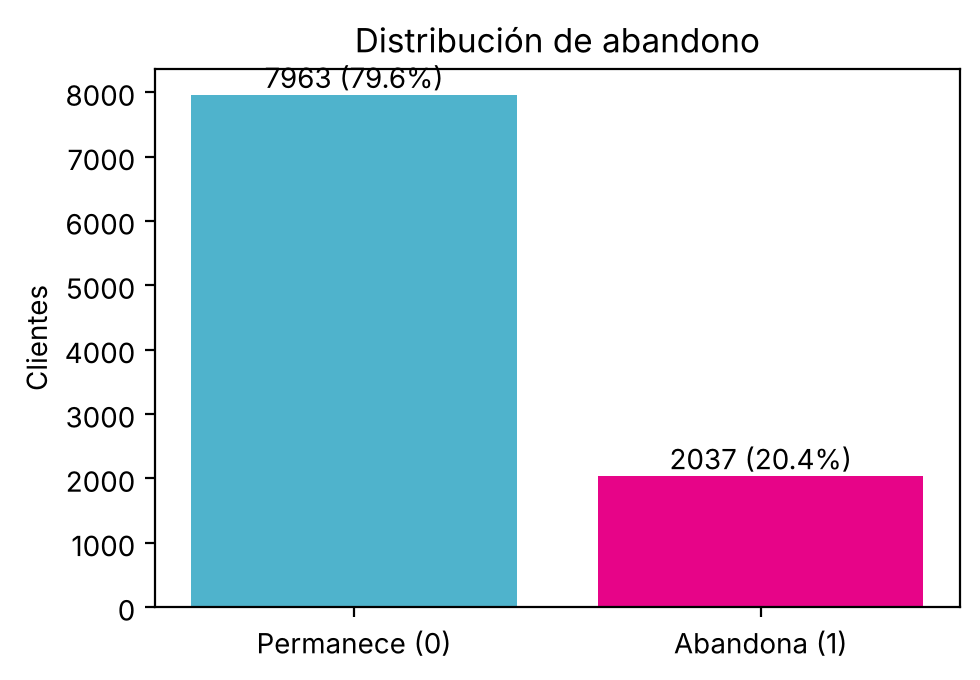

In [5]:
conteo = df["abandono"].value_counts().sort_index()
proporcion = df["abandono"].value_counts(normalize=True).sort_index()
print(pd.DataFrame({"conteo": conteo, "proporción": proporcion.round(4)}))

fig, ax = plt.subplots(figsize=(5, 3.5))
ax.bar(["Permanece (0)", "Abandona (1)"], conteo.values, color=["#4FB3CC", "#E70488"])
for i, v in enumerate(conteo.values):
    ax.text(i, v, f"{v} ({proporcion.values[i]:.1%})", ha="center", va="bottom")
ax.set_title("Distribución de abandono")
ax.set_ylabel("Clientes")
plt.tight_layout(); plt.show()

                      count       mean       std     min       25%        50%        75%        max
edad                10000.0      38.92     10.49   18.00     32.00      37.00      44.00      92.00
puntaje_crediticio  10000.0     650.53     96.65  350.00    584.00     652.00     718.00     850.00
saldo               10000.0   76485.89  62397.41    0.00      0.00   97198.54  127644.24  250898.09
salario_estimado    10000.0  100090.24  57510.49   11.58  51002.11  100193.92  149388.25  199992.48


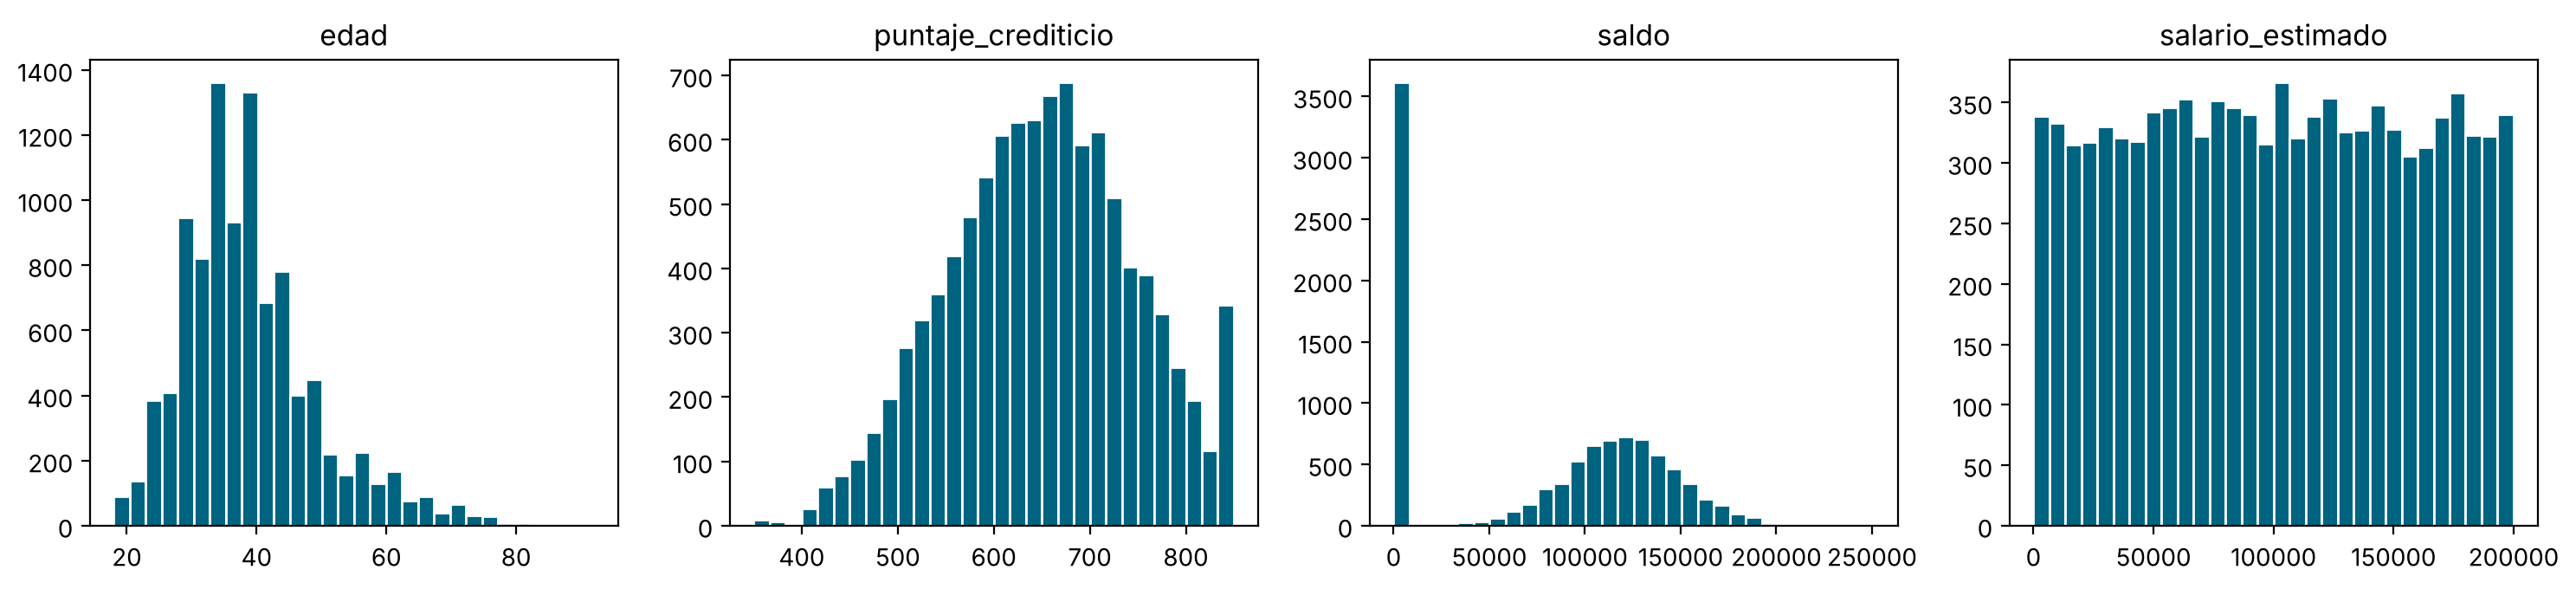

Clientes con saldo = 0: 3617 (36.2%)


In [6]:
continuas = ["edad", "puntaje_crediticio", "saldo", "salario_estimado"]
print(df[continuas].describe().T.round(2))

fig, ejes = plt.subplots(1, 4, figsize=(15, 3.5))
for ax, v in zip(ejes, continuas):
    ax.hist(df[v], bins=30, color="#00637F", edgecolor="white")
    ax.set_title(v)
plt.tight_layout(); plt.show()

print("Clientes con saldo = 0:", int((df["saldo"] == 0).sum()), f"({(df['saldo'] == 0).mean():.1%})")

In [7]:
for v in ["pais", "sexo", "numero_productos", "miembro_activo"]:
    t = pd.DataFrame({"conteo": df[v].value_counts().sort_index(),
                      "proporción": df[v].value_counts(normalize=True).sort_index().round(4)})
    print(f"--- {v} ---")
    print(t, "\n")

--- pais ---
          conteo  proporción
pais                        
Francia     5014      0.5014
Alemania    2509      0.2509
España      2477      0.2477 

--- sexo ---
        conteo  proporción
sexo                      
Mujer     4543      0.4543
Hombre    5457      0.5457 

--- numero_productos ---
                  conteo  proporción
numero_productos                    
1                   5084      0.5084
2                   4590      0.4590
3                    266      0.0266
4                     60      0.0060 

--- miembro_activo ---
                conteo  proporción
miembro_activo                    
0                 4849      0.4849
1                 5151      0.5151 



### Respuesta — Sección 2

**5. ¿Qué porcentaje de la base abandonó? ¿Por qué un clasificador que siempre diga «permanece» ya parece bueno si uno solo mira la *accuracy*?**
Abandonaron **2.037 de 10.000 clientes, el 20,4 %**. El 79,6 % permanece. Un clasificador que diga siempre «permanece» acierta en el 79,6 % de los casos sin usar ninguna variable. Esa exactitud parece alta, pero su sensibilidad es **0**: no detecta a ninguno de los clientes que se van, que son justamente los que le importan al área de retención. Con clases desbalanceadas, la exactitud premia acertar la clase mayoritaria. Por eso hay que mirarla junto con la sensibilidad y la especificidad (sección 6).

Otros rasgos del univariado: la edad tiene sesgo a la derecha (mediana 37, máximo 92). El saldo tiene una masa grande en cero (3.617 clientes, 36,2 %) y luego una campana alrededor de 120.000. El puntaje crediticio y el salario estimado no muestran nada raro: el salario es casi uniforme entre 0 y 200.000. Francia concentra la mitad de los clientes, y el 97 % de la base tiene 1 o 2 productos.